CLEANING DATA

1. INSTALL DEPENDENCIES

In [1]:
!pip -q install "kagglehub[pandas-datasets]" pandas numpy matplotlib seaborn

2. IMPORTS

In [18]:
import os
import re
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

warnings.filterwarnings("ignore")

3. LOAD THE DATASET FROM KAGGLE

In [19]:
dataset_handle = "ahmedmohamed2003/retail-store-sales-dirty-for-data-cleaning"

dataset_path = kagglehub.dataset_download(dataset_handle)

print("Dataset downloaded successfully!")
print("Dataset folder:", dataset_path)

# Find CSV files inside the downloaded dataset
csv_files = glob.glob(
    os.path.join(dataset_path, "**", "*.csv"),
    recursive=True
)

if not csv_files:
    raise FileNotFoundError(
        "No CSV file found in the downloaded dataset folder."
    )

print("\nAvailable CSV files:")
for i, file in enumerate(csv_files, start=1):
    print(f"{i}. {os.path.basename(file)}")

# Load the first CSV file
# If multiple CSV files are present, change csv_files[0]
# to the appropriate file shown above.
df = pd.read_csv(csv_files[0], low_memory=False)

print("\nSelected file:", os.path.basename(csv_files[0]))
print("\nFirst 5 records:")
print(df.head())


Using Colab cache for faster access to the 'retail-store-sales-dirty-for-data-cleaning' dataset.
Dataset downloaded successfully!
Dataset folder: /kaggle/input/retail-store-sales-dirty-for-data-cleaning

Available CSV files:
1. retail_store_sales.csv

Selected file: retail_store_sales.csv

First 5 records:
  Transaction ID Customer ID       Category          Item  Price Per Unit  \
0    TXN_6867343     CUST_09     Patisserie   Item_10_PAT            18.5   
1    TXN_3731986     CUST_22  Milk Products  Item_17_MILK            29.0   
2    TXN_9303719     CUST_02       Butchers   Item_12_BUT            21.5   
3    TXN_9458126     CUST_06      Beverages   Item_16_BEV            27.5   
4    TXN_4575373     CUST_05           Food   Item_6_FOOD            12.5   

   Quantity  Total Spent  Payment Method Location Transaction Date  \
0      10.0        185.0  Digital Wallet   Online       2024-04-08   
1       9.0        261.0  Digital Wallet   Online       2023-07-23   
2       2.0        

4. INITAL DATA INSPECTION

In [20]:
print("\n========== INITIAL DATA INSPECTION ==========")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
print(df.describe(include="all").T)

# Keep a copy for before-and-after comparisons
df_before = df.copy()


========== INITIAL DATA INSPECTION ==========
Number of rows: 12575
Number of columns: 11

Column names:
['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit', 'Quantity', 'Total Spent', 'Payment Method', 'Location', 'Transaction Date', 'Discount Applied']

Data types:
Transaction ID       object
Customer ID          object
Category             object
Item                 object
Price Per Unit      float64
Quantity            float64
Total Spent         float64
Payment Method       object
Location             object
Transaction Date     object
Discount Applied     object
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12575 entries, 0 to 12574
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction ID    12575 non-null  object 
 1   Customer ID       12575 non-null  object 
 2   Category          12575 non-null  object 
 3   Item              1

5. CREATING A DATA QUALITY REPORT

In [21]:
def create_quality_report(data):
    report = pd.DataFrame({
        "Data Type": data.dtypes.astype(str),
        "Missing Values": data.isna().sum(),
        "Missing Percentage": (
            data.isna().mean() * 100
        ).round(2),
        "Unique Values": data.nunique(dropna=True)
    })

    return report


quality_before = create_quality_report(df)

print("\n========== DATA QUALITY REPORT: BEFORE ==========")
print(quality_before)

quality_before.to_csv("quality_report_before.csv")


========== DATA QUALITY REPORT: BEFORE ==========
                 Data Type  Missing Values  Missing Percentage  Unique Values
Transaction ID      object               0                0.00          12575
Customer ID         object               0                0.00             25
Category            object               0                0.00              8
Item                object            1213                9.65            200
Price Per Unit     float64             609                4.84             25
Quantity           float64             604                4.80             10
Total Spent        float64             604                4.80            227
Payment Method      object               0                0.00              3
Location            object               0                0.00              2
Transaction Date    object               0                0.00           1114
Discount Applied    object            4199               33.39              2


6. STANDARDIZE COLUMN NAMES

In [22]:
# Example: "Transaction Date" becomes "transaction_date"

def clean_column_name(column):
    column = str(column).strip().lower()
    column = re.sub(r"[^a-z0-9]+", "_", column)
    return column.strip("_")


df.columns = [clean_column_name(c) for c in df.columns]

# Make duplicate column names unique
new_columns = []
counts = {}

for column in df.columns:
    counts[column] = counts.get(column, 0) + 1

    if counts[column] == 1:
        new_columns.append(column)
    else:
        new_columns.append(f"{column}_{counts[column]}")

df.columns = new_columns

print("\nStandardized column names:")
print(df.columns.tolist())


Standardized column names:
['transaction_id', 'customer_id', 'category', 'item', 'price_per_unit', 'quantity', 'total_spent', 'payment_method', 'location', 'transaction_date', 'discount_applied']


7. CLEAN TEXT VALUES AND MISSING VALUE PLACEHOLDERS

In [23]:
missing_placeholders = [
    "", " ", "na", "n/a", "nan", "none",
    "null", "missing", "not available", "unknown"
]

for column in df.select_dtypes(include=["object", "string"]).columns:
    df[column] = df[column].astype("string").str.strip()

    # Replace common missing-value labels with actual NaN
    df[column] = df[column].replace(
        {value: np.nan for value in missing_placeholders},
        regex=False
    )

# Standardize common categorical/text fields
for column in df.select_dtypes(include=["object", "string"]).columns:
    name = column.lower()

    if any(word in name for word in [
        "category", "payment_method", "payment_type",
        "location", "gender"
    ]):
        df[column] = df[column].str.lower().str.strip()
        df[column] = df[column].str.replace(
            r"\s+", " ", regex=True
        )
        df[column] = df[column].str.title()

print("\nText values standardized.")



Text values standardized.


8. REMOVE DUPLICATE RECORDS

In [24]:
duplicates_before = int(df.duplicated().sum())

print("\nExact duplicate rows found:", duplicates_before)

df = df.drop_duplicates().copy()

print("Duplicate rows removed:", duplicates_before - df.duplicated().sum())
print("Rows after duplicate removal:", len(df))



Exact duplicate rows found: 0
Duplicate rows removed: 0
Rows after duplicate removal: 12575


9. CORRECT DATA TYPES

In [25]:
# Detect date/time columns using their column names

for column in df.columns:
    name = column.lower()

    if any(word in name for word in [
        "date", "datetime", "timestamp"
    ]):
        parsed_dates = pd.to_datetime(
            df[column], errors="coerce"
        )

        # Replace only if at least one valid date was detected
        if parsed_dates.notna().any():
            df[column] = parsed_dates

# Convert numeric-looking text columns to numeric
for column in df.select_dtypes(include=["object", "string"]).columns:
    name = column.lower()

    # Avoid converting IDs and descriptive text
    if any(word in name for word in [
        "id", "name", "category", "method",
        "location", "address", "gender"
    ]):
        continue

    original = df[column].astype("string")

    # Remove common formatting from currency and comma-separated values
    cleaned = original.str.replace(
        r"[$₹€£,]", "", regex=True
    ).str.replace("%", "", regex=False).str.strip()

    converted = pd.to_numeric(cleaned, errors="coerce")

    valid_original = original.notna().sum()

    if valid_original > 0:
        conversion_ratio = converted.notna().sum() / valid_original

        # Convert only when most non-missing values are numeric
        if conversion_ratio >= 0.80:
            df[column] = converted

# Report the corrected data types
print("\n========== DATA TYPES AFTER CORRECTION ==========")
print(df.dtypes)



========== DATA TYPES AFTER CORRECTION ==========
transaction_id      string[python]
customer_id         string[python]
category            string[python]
item                string[python]
price_per_unit             float64
quantity                   float64
total_spent                float64
payment_method      string[python]
location            string[python]
transaction_date    datetime64[ns]
discount_applied    string[python]
dtype: object


10. HANDLE IMVALID NUMERIC VALUES

In [26]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()

# Negative values in these columns are usually invalid.
# Adjust this list if your dataset has different business rules.
non_negative_keywords = [
    "price", "quantity", "amount", "total",
    "spent", "sales", "revenue", "discount"
]

for column in numeric_columns:
    name = column.lower()

    if any(word in name for word in non_negative_keywords):
        df.loc[df[column] < 0, column] = np.nan

print("\nInvalid negative business values changed to missing values.")


Invalid negative business values changed to missing values.


11. HANDLE MISSING VALUES

In [27]:
missing_before_imputation = df.isna().sum()

print("\n========== MISSING VALUES BEFORE IMPUTATION ==========")
print(missing_before_imputation[missing_before_imputation > 0])

for column in df.columns:
    if df[column].isna().sum() == 0:
        continue

    # Numeric columns: fill with median
    if pd.api.types.is_numeric_dtype(df[column]):
        median_value = df[column].median()

        if pd.notna(median_value):
            df[column] = df[column].fillna(median_value)

    # Date columns: fill with mode if available
    elif pd.api.types.is_datetime64_any_dtype(df[column]):
        mode_values = df[column].mode(dropna=True)

        if not mode_values.empty:
            df[column] = df[column].fillna(mode_values.iloc[0])

    # Text/category columns: fill with mode,
    # or "Unknown" when no mode is available
    else:
        mode_values = df[column].mode(dropna=True)

        if not mode_values.empty:
            df[column] = df[column].fillna(mode_values.iloc[0])
        else:
            df[column] = df[column].fillna("Unknown")

print("\nMissing values handled.")



========== MISSING VALUES BEFORE IMPUTATION ==========
item                1213
price_per_unit       609
quantity             604
total_spent          604
discount_applied    4199
dtype: int64

Missing values handled.


12. DETECT AND TREAT NUMERICAL OUTLIERS USING IQR

In [28]:
# Outliers are capped at the IQR boundaries (not deleted).
# ID-like columns are excluded.

outlier_records = []

for column in df.select_dtypes(include=np.number).columns:
    name = column.lower()

    if "id" in name:
        continue

    series = df[column].dropna()

    if len(series) < 4 or series.nunique() < 4:
        continue

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    if iqr == 0:
        continue

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    )

    outlier_count = int(outlier_mask.sum())

    outlier_records.append({
        "Column": column,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outliers Detected": outlier_count
    })

    df[column] = df[column].clip(
        lower=lower_bound,
        upper=upper_bound
    )

outlier_report = pd.DataFrame(outlier_records)

print("\n========== OUTLIER REPORT ==========")
if outlier_report.empty:
    print("No eligible numerical columns for IQR analysis.")
else:
    print(outlier_report.to_string(index=False))

outlier_report.to_csv("outlier_report.csv", index=False)


========== OUTLIER REPORT ==========
        Column  Lower Bound  Upper Bound  Outliers Detected
price_per_unit        -13.0         59.0                  0
      quantity         -4.5         15.5                  0
   total_spent       -138.5        377.5                157


13. FINAL DATA QUALITY REPORT AND BEFORE-VS-AFTER SUMMARY

In [29]:
quality_after = create_quality_report(df)

print("\n========== DATA QUALITY REPORT: AFTER ==========")
print(quality_after)

quality_after.to_csv("quality_report_after.csv")

summary = pd.DataFrame({
    "Metric": [
        "Number of rows",
        "Number of columns",
        "Missing cells",
        "Exact duplicate rows",
        "Numeric columns",
        "Text columns",
        "Date/time columns"
    ],
    "Before Cleaning": [
        len(df_before),
        len(df_before.columns),
        int(df_before.isna().sum().sum()),
        int(df_before.duplicated().sum()),
        len(df_before.select_dtypes(include=np.number).columns),
        len(df_before.select_dtypes(
            include=["object", "string"]
        ).columns),
        len(df_before.select_dtypes(
            include=["datetime", "datetimetz"]
        ).columns)
    ],
    "After Cleaning": [
        len(df),
        len(df.columns),
        int(df.isna().sum().sum()),
        int(df.duplicated().sum()),
        len(df.select_dtypes(include=np.number).columns),
        len(df.select_dtypes(
            include=["object", "string"]
        ).columns),
        len(df.select_dtypes(
            include=["datetime", "datetimetz"]
        ).columns)
    ]
})

print("\n========== BEFORE VS AFTER SUMMARY ==========")
print(summary.to_string(index=False))

summary.to_csv("before_after_summary.csv", index=False)



========== DATA QUALITY REPORT: AFTER ==========
                       Data Type  Missing Values  Missing Percentage  \
transaction_id            string               0                 0.0   
customer_id               string               0                 0.0   
category                  string               0                 0.0   
item                      string               0                 0.0   
price_per_unit           float64               0                 0.0   
quantity                 float64               0                 0.0   
total_spent              float64               0                 0.0   
payment_method            string               0                 0.0   
location                  string               0                 0.0   
transaction_date  datetime64[ns]               0                 0.0   
discount_applied          string               0                 0.0   

                  Unique Values  
transaction_id            12575  
customer_id      

14. VISUALISE MISSING VALUES BEFORE AND AFTER CLEANING

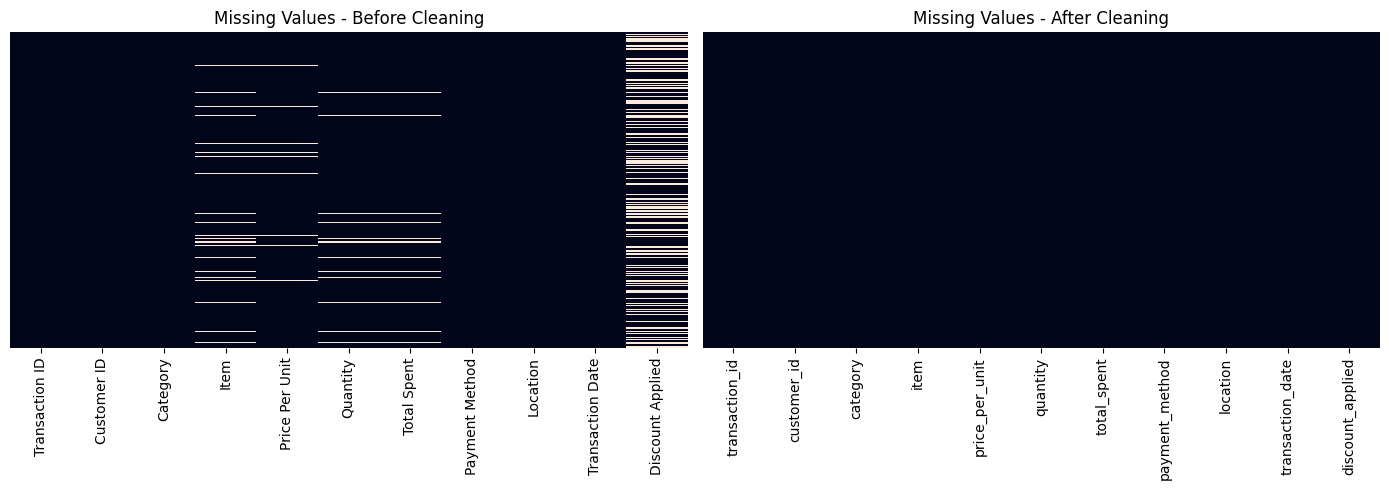

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    df_before.isna(),
    cbar=False,
    yticklabels=False,
    ax=axes[0]
)
axes[0].set_title("Missing Values - Before Cleaning")

sns.heatmap(
    df.isna(),
    cbar=False,
    yticklabels=False,
    ax=axes[1]
)
axes[1].set_title("Missing Values - After Cleaning")

plt.tight_layout()
plt.savefig("missing_values_before_after.png", dpi=300)
plt.show()


15. VISUALISE OUTLIER COUNTS

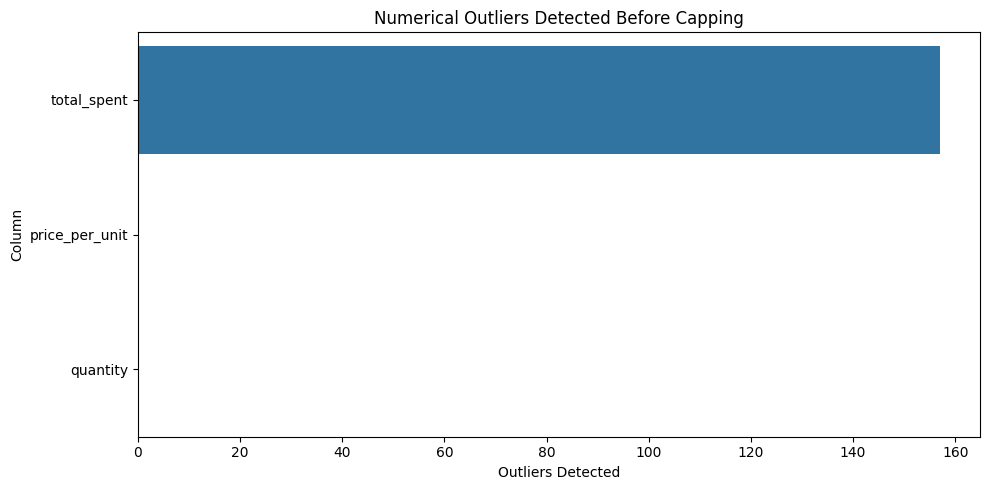

In [31]:
if not outlier_report.empty:
    plot_data = outlier_report.sort_values(
        "Outliers Detected", ascending=False
    )

    plt.figure(figsize=(10, 5))
    sns.barplot(
        data=plot_data,
        x="Outliers Detected",
        y="Column"
    )
    plt.title("Numerical Outliers Detected Before Capping")
    plt.tight_layout()
    plt.savefig("outlier_report_chart.png", dpi=300)
    plt.show()


16. EXPORT THE CLEANED DATASET

In [32]:
output_file = "retail_store_sales_cleaned.csv"

df.to_csv(output_file, index=False)

print("\n========== CLEANING COMPLETED ==========")
print("Original shape:", df_before.shape)
print("Cleaned shape:", df.shape)
print("Remaining missing cells:", int(df.isna().sum().sum()))
print("Remaining duplicate rows:", int(df.duplicated().sum()))
print("Cleaned file saved as:", output_file)

print("\nFirst 5 cleaned records:")
print(df.head())

print("\nGenerated output files:")
for file in [
    output_file,
    "quality_report_before.csv",
    "quality_report_after.csv",
    "outlier_report.csv",
    "before_after_summary.csv",
    "missing_values_before_after.png",
    "outlier_report_chart.png"
]:
    if os.path.exists(file):
        print("-", file)



========== CLEANING COMPLETED ==========
Original shape: (12575, 11)
Cleaned shape: (12575, 11)
Remaining missing cells: 0
Remaining duplicate rows: 0
Cleaned file saved as: retail_store_sales_cleaned.csv

First 5 cleaned records:
  transaction_id customer_id       category          item  price_per_unit  \
0    TXN_6867343     CUST_09     Patisserie   Item_10_PAT            18.5   
1    TXN_3731986     CUST_22  Milk Products  Item_17_MILK            29.0   
2    TXN_9303719     CUST_02       Butchers   Item_12_BUT            21.5   
3    TXN_9458126     CUST_06      Beverages   Item_16_BEV            27.5   
4    TXN_4575373     CUST_05           Food   Item_6_FOOD            12.5   

   quantity  total_spent  payment_method location transaction_date  \
0      10.0        185.0  Digital Wallet   Online       2024-04-08   
1       9.0        261.0  Digital Wallet   Online       2023-07-23   
2       2.0         43.0     Credit Card   Online       2022-10-05   
3       9.0        247.5 